Importing required packages

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
print(torch.__version__)

2.5.1+cu121


Loading an image

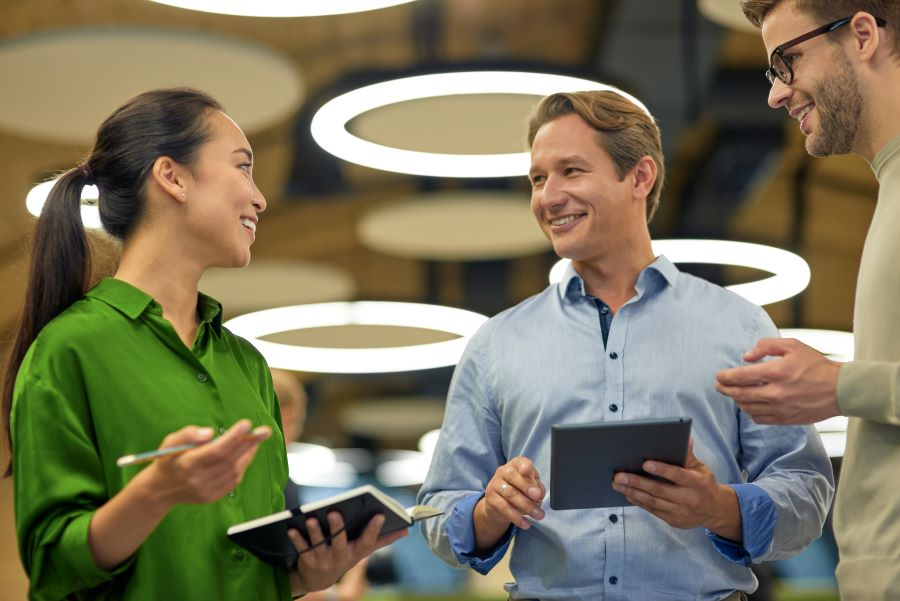

In [ ]:
img = Image.open('image.jpg')

img

In [ ]:
transforms = T.Compose([T.Resize(450),
                        T.ToTensor()])

In [ ]:
img_tensor = transforms(img)

img_tensor

tensor([[[0.4471, 0.4471, 0.4471,  ..., 0.2863, 0.2627, 0.2627],
         [0.4471, 0.4471, 0.4471,  ..., 0.2667, 0.2510, 0.2588],
         [0.4471, 0.4471, 0.4471,  ..., 0.2588, 0.2549, 0.2667],
         ...,
         [0.6118, 0.6157, 0.6196,  ..., 0.4471, 0.4431, 0.4392],
         [0.6078, 0.6118, 0.6157,  ..., 0.4510, 0.4471, 0.4431],
         [0.6078, 0.6039, 0.6118,  ..., 0.4510, 0.4471, 0.4431]],

        [[0.3451, 0.3451, 0.3451,  ..., 0.2039, 0.1804, 0.1804],
         [0.3451, 0.3451, 0.3451,  ..., 0.1843, 0.1686, 0.1765],
         [0.3451, 0.3451, 0.3451,  ..., 0.1765, 0.1725, 0.1843],
         ...,
         [0.4510, 0.4549, 0.4588,  ..., 0.4235, 0.4235, 0.4196],
         [0.4471, 0.4510, 0.4549,  ..., 0.4275, 0.4275, 0.4235],
         [0.4471, 0.4431, 0.4510,  ..., 0.4314, 0.4353, 0.4314]],

        [[0.1451, 0.1451, 0.1451,  ..., 0.1294, 0.1098, 0.1137],
         [0.1451, 0.1451, 0.1451,  ..., 0.1098, 0.0980, 0.1098],
         [0.1451, 0.1451, 0.1451,  ..., 0.1020, 0.1020, 0.

In [ ]:
img_tensor.shape

torch.Size([3, 450, 673])

In [ ]:
img_tensor = img_tensor.unsqueeze(0)

img_tensor.shape

torch.Size([1, 3, 450, 673])

### Définition d'un filtre
Les filtres permettent le renforcement, la détection des contours, le flou et l’embossage.

In [ ]:
sharpen_kernel = [[[[0, -1, 0]],
                   [[-1, 5, -1]],
                   [[0, -1, 0]]]]

In [ ]:
sharpen_filter = torch.Tensor(sharpen_kernel)

sharpen_filter.shape

torch.Size([1, 3, 1, 3])

In [ ]:
conv_tensor = F.conv2d(img_tensor, sharpen_filter, padding=0)

conv_tensor.shape

torch.Size([1, 1, 450, 671])

In [ ]:
conv_img = conv_tensor[0, :, :, :]

conv_img.shape

torch.Size([1, 450, 671])

In [ ]:
conv_img = conv_img.numpy().squeeze()

conv_img.shape

(450, 671)

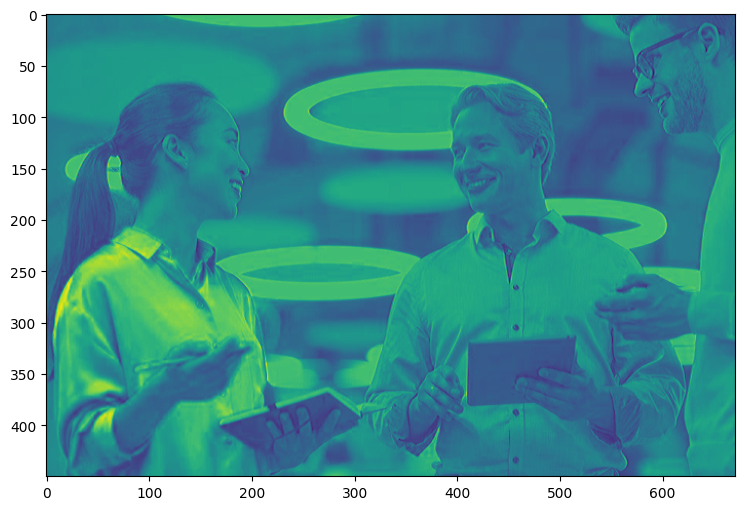

In [ ]:
plt.figure(figsize = (12, 6))

plt.imshow(conv_img)

In [ ]:
pool = nn.MaxPool2d(2, 2)

pool

MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)

In [ ]:
pool_tensor = pool(conv_tensor)

pool_tensor.shape

torch.Size([1, 1, 225, 335])

In [ ]:
pool_img = pool_tensor[0, :, :, :]

pool_img.shape

torch.Size([1, 225, 335])

In [ ]:
pool_img = pool_img.numpy().squeeze()

pool_img.shape

(225, 335)

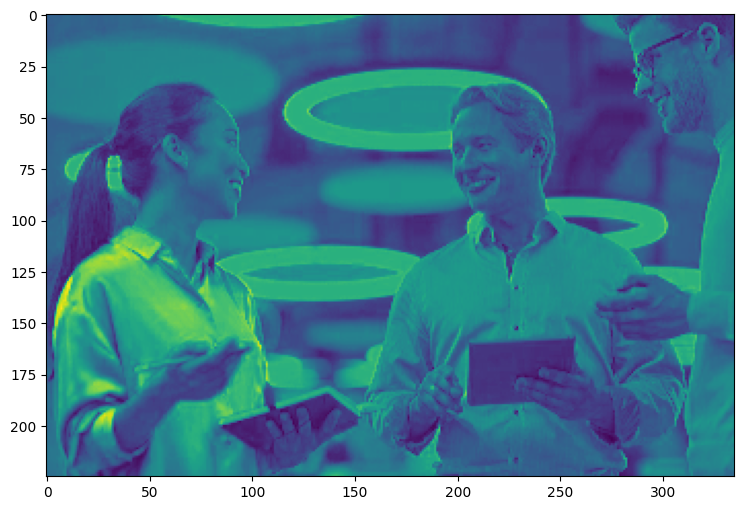

In [ ]:
plt.figure(figsize = (12, 6))

plt.imshow(pool_img)

In [ ]:
def apply_kernel_and_show(img_tensor, kernel):
  filter = torch.Tensor(kernel)

  conv_tensor = F.conv2d(img_tensor, filter, padding=0)

  conv_img = conv_tensor[0, :, :, :]
  conv_img = conv_img.numpy().squeeze()

  pool = nn.MaxPool2d(2, 2)

  pool_tensor = pool(conv_tensor)

  pool_img = pool_tensor[0, :, :, :]
  pool_img = pool_img.numpy().squeeze()

  fig, (ax1, ax2) = plt.subplots(1, 2)
  fig.set_size_inches(16, 6)

  fig.suptitle('Convolutional output and Pooling output')

  ax1.imshow(conv_img)
  ax2.imshow(pool_img)

Les noyaux de détection des contours horizontaux et verticaux, connus sous le nom de filtres de Prewitt

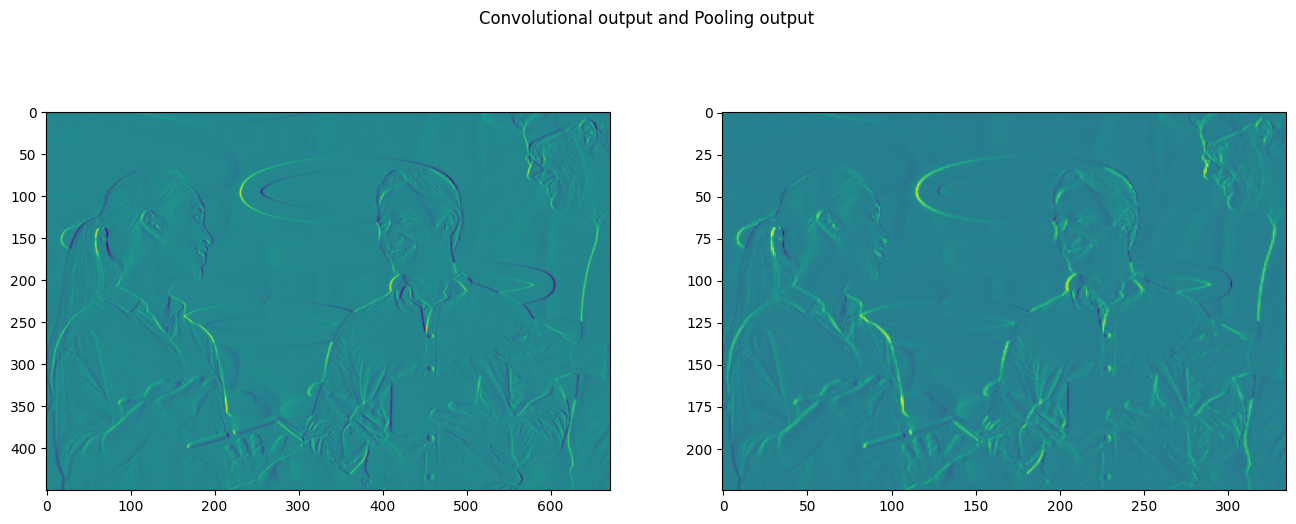

In [ ]:
vertical_edge_kernel = [[[[-1, 0, 1]],
                       [[-1, 0, 1]],
                       [[-1, 0, 1]]]]

apply_kernel_and_show(img_tensor, vertical_edge_kernel)

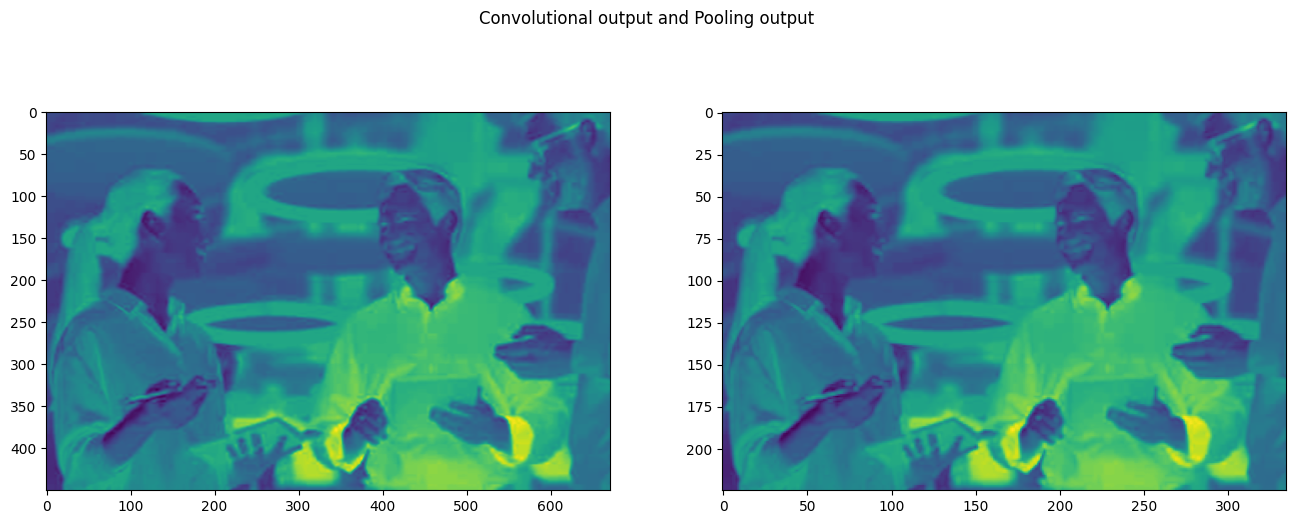

In [ ]:
horizontal_edge_kernel = [[[[-1, -1, -1]],
                           [[0, 0, 0]],
                           [[1, 1, 1]]]]

apply_kernel_and_show(img_tensor, horizontal_edge_kernel)

Ci-dessous se trouvent les noyaux de détection des contours horizontaux et verticaux, connus sous le nom de filtres de Sobel.

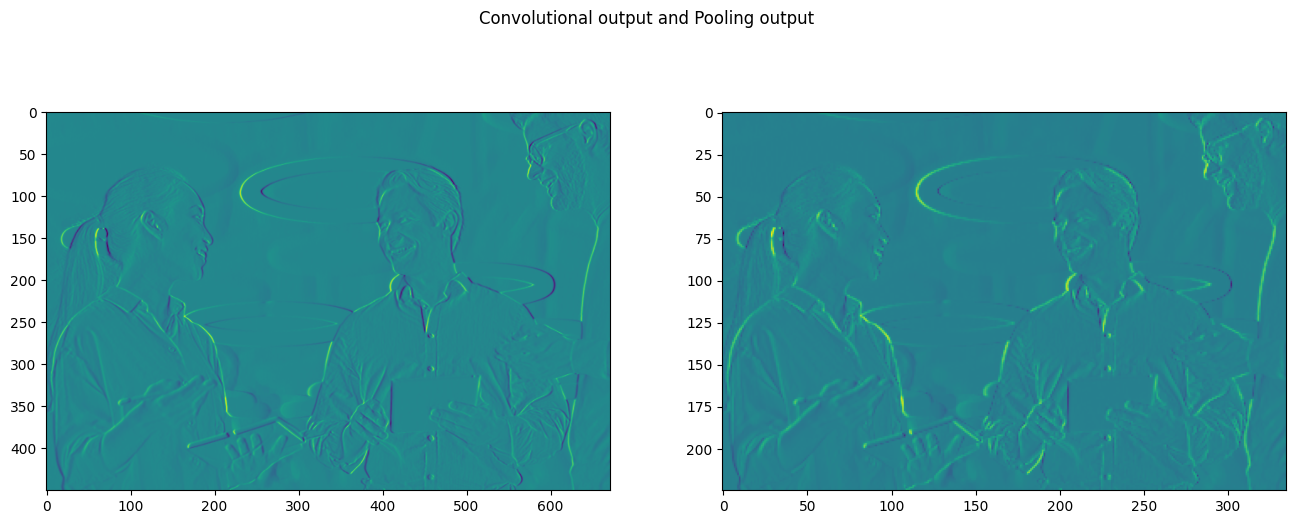

In [ ]:
vertical_edge_kernel = [[[[-1, 0, 1]],
                         [[-2, 0, 2]],
                         [[-1, 0, 1]]]]

apply_kernel_and_show(img_tensor, vertical_edge_kernel)

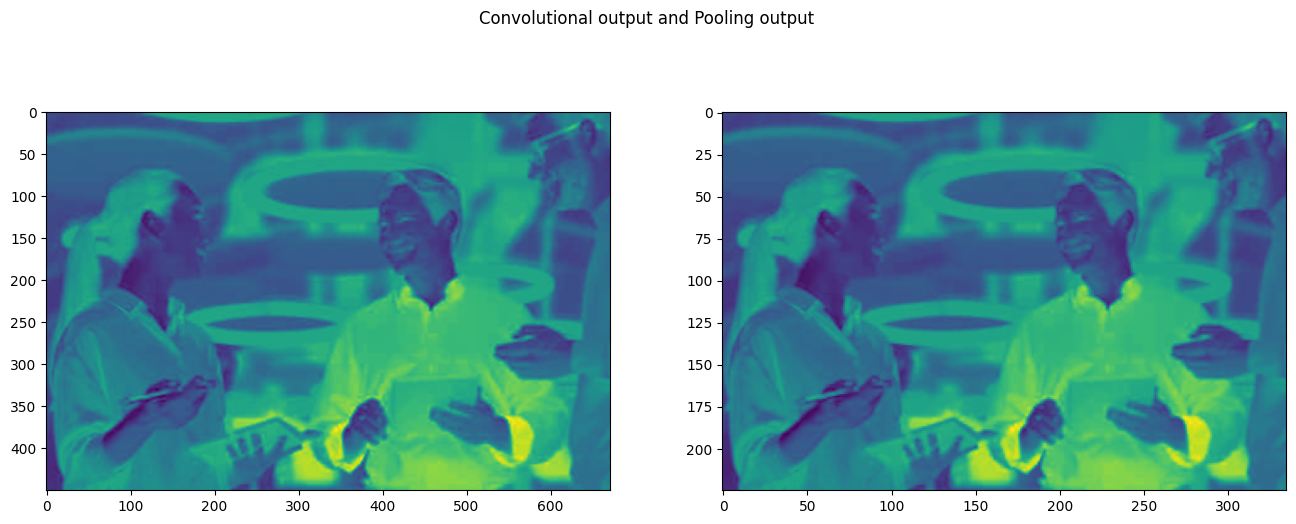

In [ ]:
horizontal_edge_kernel = [[[[-1, -2, -1]],
                           [[0, 0, 0]],
                           [[1, 2, 1]]]]

apply_kernel_and_show(img_tensor, horizontal_edge_kernel)

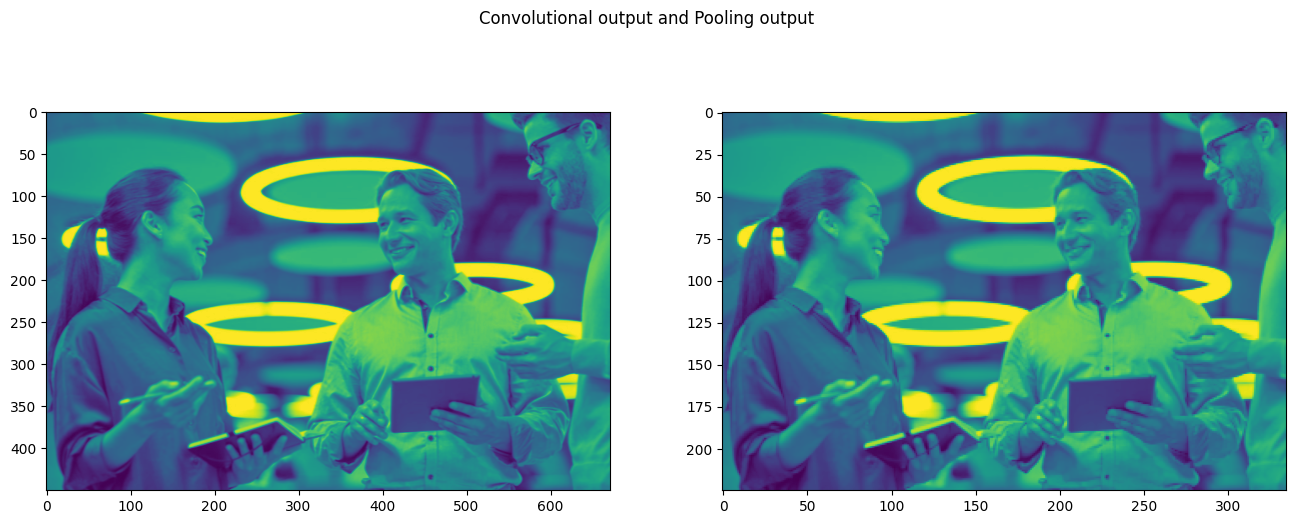

In [ ]:
gaussian_blur_kernel = [[[[1/16, 1/8, 1/16]],
                           [[1/8, 1/4, 1/8]],
                           [[1/16, 1/8, 1/16]]]]

apply_kernel_and_show(img_tensor, gaussian_blur_kernel)

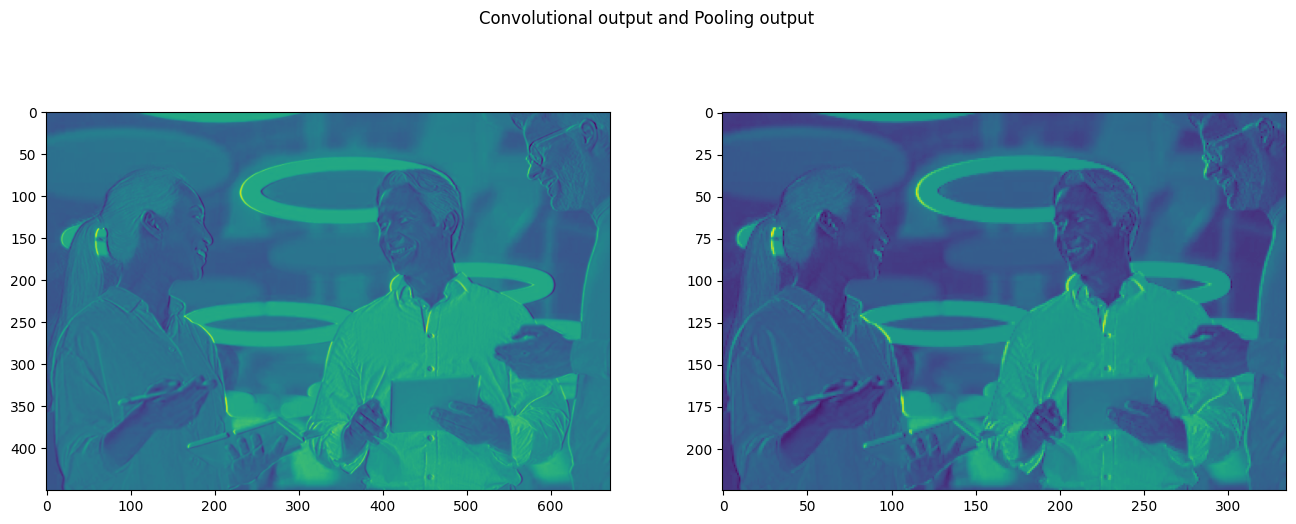

In [ ]:
emboss_kernel = [[[[-2, -1, 0]],
                  [[-1, 1, 1]],
                  [[0, 1, 2]]]]

apply_kernel_and_show(img_tensor, emboss_kernel)